# Домашнее задание №1 — полнота библиографических данных по лингвистике

**Вопрос:** насколько полно представлены сведения об авторах, годе первой публикации и языках изданий в результатах поиска `subject:linguistics` Open Library?

In [35]:
import json
import time
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
URL = "https://openlibrary.org/search.json"
QUERY = "subject:linguistics"
FIELDS = "key,title,author_name,first_publish_year,language,edition_count"

PAGE_SIZE = 2000
MAX_REQUESTS = 30

email = input("Укажи email для User-Agent: ")

HEADERS = {
    "User-Agent": f"LinguisticsResearch/1.0 (contact: {email})"
}

CACHE_DIR = Path("ol_pages")
CACHE_DIR.mkdir(exist_ok=True)

In [37]:
def get_json(url, params, attempts=3):
    for attempt in range(1, attempts + 1):
        try:
            response = requests.get(
                url,
                params=params,
                headers=HEADERS,
                timeout=120
            )

        except (requests.exceptions.Timeout,
                requests.exceptions.ConnectionError):
            print(f"Попытка {attempt}: сервер не ответил")
            time.sleep(5)
            continue

        if response.status_code in (429, 500, 502, 503, 504):
            print(f"Попытка {attempt}: ошибка {response.status_code}")
            time.sleep(5)
            continue

        response.raise_for_status()
        return response.json()

    raise RuntimeError("Не удалось получить данные")

In [38]:
all_records = []
total = None

for i in range(MAX_REQUESTS):
    offset = i * PAGE_SIZE

    if total is not None and offset >= total:
        break

    page_file = CACHE_DIR / f"page_{offset}.json"

    if page_file.exists():
        with open(page_file, "r", encoding="utf-8") as f:
            data = json.load(f)

    else:
        params = {
            "q": QUERY,
            "limit": PAGE_SIZE,
            "offset": offset,
            "fields": FIELDS,
            "sort": "key"
        }

        data = get_json(URL, params)

        with open(page_file, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

        time.sleep(2)

    if total is None:
        total = data["numFound"]
        print("Всего найдено:", total)

    elif data["numFound"] != total:
        raise RuntimeError("Количество результатов изменилось")

    docs = data.get("docs", [])

    expected = min(PAGE_SIZE, total - offset)

    if len(docs) != expected:
        raise RuntimeError(
            f"Неполная порция: получено {len(docs)}, ожидалось {expected}"
        )

    all_records.extend(docs)

    print(f"Порция {i + 1}: собрано {len(all_records)} из {total}")

if total is None or len(all_records) != total:
    raise RuntimeError("Удалось собрать не все записи")

print("Сбор завершён:", len(all_records))

Всего найдено: 47080
Порция 1: собрано 2000 из 47080
Порция 2: собрано 4000 из 47080
Порция 3: собрано 6000 из 47080
Порция 4: собрано 8000 из 47080
Порция 5: собрано 10000 из 47080
Порция 6: собрано 12000 из 47080
Порция 7: собрано 14000 из 47080
Порция 8: собрано 16000 из 47080
Порция 9: собрано 18000 из 47080
Порция 10: собрано 20000 из 47080
Порция 11: собрано 22000 из 47080
Порция 12: собрано 24000 из 47080
Порция 13: собрано 26000 из 47080
Порция 14: собрано 28000 из 47080
Порция 15: собрано 30000 из 47080
Порция 16: собрано 32000 из 47080
Порция 17: собрано 34000 из 47080
Порция 18: собрано 36000 из 47080
Порция 19: собрано 38000 из 47080
Порция 20: собрано 40000 из 47080
Порция 21: собрано 42000 из 47080
Порция 22: собрано 44000 из 47080
Порция 23: собрано 46000 из 47080
Порция 24: собрано 47080 из 47080
Сбор завершён: 47080


In [39]:
COLUMNS = ["key", "title", "author_name", "first_publish_year", "language", "edition_count"]

df_test = pd.DataFrame(all_records)
for col in COLUMNS:
    if col not in df_test.columns:
        df_test[col] = None

df_test = df_test[COLUMNS].copy()
df_test["first_publish_year"] = pd.to_numeric(df_test["first_publish_year"], errors="coerce")

print("Уникальных произведений:", df_test["key"].nunique())

if df_test["key"].isna().any() or df_test["key"].nunique() != len(df_test):
    raise RuntimeError("Есть повторяющиеся или отсутствующие идентификаторы произведений!")
if len(df_test) != total:
    raise RuntimeError("Число строк не совпадает с numFound.")

display(df_test.head())

Уникальных произведений: 47080


,key,title,author_name,first_publish_year,language,edition_count
0,/works/OL10000109W,Problemes De Cohesion Syntaxique De 1550,[Janine Baudry],1998.0,[fre],2
1,/works/OL10002933W,La méthode dialectométrique appliquée aux lang...,[Guarisma G.],1986.0,[fre],2
2,/works/OL10005151W,Le contrôle dans les systèmes à base de connai...,[Bruno Bachimont],1994.0,[fre],2
3,/works/OL10005605W,Éléments de syntaxe structurale,[Lucien Tesniere],1966.0,[fre],1
4,/works/OL10005901W,Le langage,[Brigitte Frelat-Kahn],1989.0,[fre],2


In [40]:
df_test.to_csv(
    "data.csv",
    index=False,
    encoding="utf-8"
)

In [41]:
def is_missing(value):
    if isinstance(value, (list, tuple)):
        return len(value) == 0
    if isinstance(value, str):
        return value.strip() == ""
    return bool(pd.isna(value))

columns = ["author_name", "first_publish_year", "language"]
missing_flags = df_test[columns].apply(lambda column: column.map(is_missing))

summary = pd.DataFrame({
    "Пропусков": missing_flags.sum(),
    "Доля пропусков, %": (missing_flags.mean() * 100).round(2),
    "Заполнено, %": ((1 - missing_flags.mean()) * 100).round(2)
})

display(summary)

,Пропусков,"Доля пропусков, %","Заполнено, %"
author_name,2561,5.44,94.56
first_publish_year,712,1.51,98.49
language,1904,4.04,95.96


In [42]:
df_period = df_test.copy()

df_period["period"] = pd.cut(
    df_period["first_publish_year"],
    bins=[float("-inf"), 1899, 1999, float("inf")],
    labels=["До 1900", "1900–1999", "2000+"]
)

counts = df_period.groupby("period", observed=True).size()

missing_authors = df_period.groupby("period", observed=True)["author_name"].apply(
    lambda x: x.map(is_missing).mean() * 100
)
missing_languages = df_period.groupby("period", observed=True)["language"].apply(
    lambda x: x.map(is_missing).mean() * 100
)

summary_period = pd.DataFrame({
    "Количество произведений": counts,
    "Нет автора, %": missing_authors.round(2),
    "Нет языка, %": missing_languages.round(2)
})

display(summary_period)
print("Без года (не распределены по периодам):", df_period["period"].isna().sum())
assert int(counts.sum()) + int(df_period["period"].isna().sum()) == len(df_test)

,Количество произведений,"Нет автора, %","Нет языка, %"
period,,,
До 1900,1137,2.02,0.53
1900–1999,21169,6.57,3.81
2000+,24062,3.60,3.31


Без года (не распределены по периодам): 712


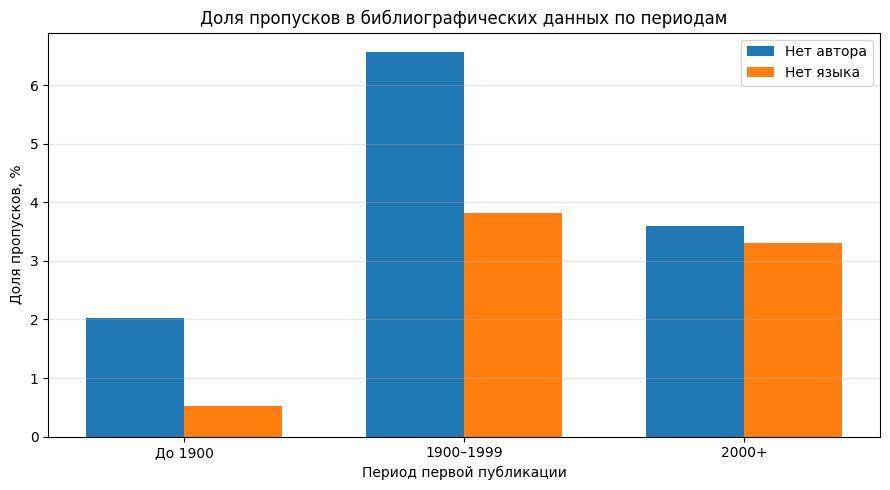

In [43]:
periods = summary_period.index
authors = summary_period["Нет автора, %"]
languages = summary_period["Нет языка, %"]

x = np.arange(len(periods))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, authors, width, label="Нет автора")
plt.bar(x + width/2, languages, width, label="Нет языка")

plt.xticks(x, periods)
plt.ylabel("Доля пропусков, %")
plt.xlabel("Период первой публикации")
plt.title("Доля пропусков в библиографических данных по периодам")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
sample = df_test.sample(n=min(12, len(df_test)), random_state=42)
display(sample[["title", "author_name", "first_publish_year", "language"]])

,title,author_name,first_publish_year,language
2874,La linguistica del novecento,[Giulio C. Lepschy],1992.0,[ita]
5011,Syntaktische Kategorien und lexikalische Klassen,[Sonja Erlenkamp],2000.0,[ger]
26032,Ökonomie und Kybernetik natürlicher Sprachen,[August Dauses],2000.0,[ger]
5080,A national study of school effectiveness for l...,[Wayne P. Thomas],2002.0,[eng]
39600,Kurs obshcheĭ lingvistiki,[Ferdinand de Saussure],1933.0,"[rus, fre]"
26712,al- Kitāb fī taʻallum al-ʻArabiȳah =,"[Kristen Brustad, Mahmoud Al-Batal, Abbas Al-T...",1995.0,"[ara, eng]"
8844,Fa lü yu yan yan jiu xin jin zhan,[Fa lü yu yan xue quan guo xue shu yan tao hui...,2010.0,[chi]
39211,Språk i fokus,"[Elisabeth Ahlsén, Jens S. Allwood]",1995.0,[swe]
45349,Izbrannye raboty po i͡a︡zykoznanii͡u︡,[Mikołaj Kruszewski],1998.0,[rus]
28403,Corpus-Based Approaches to Construction Grammar,"[Jiyoung Yoon, Stefan Th Gries]",2016.0,[eng]
